# Trabalho 3 - Partes 3 e 4: Regressão Logística e SVM

Alexsandro Narducci, Cláudio Strohaecker Junior e Lucas Cândido Belletti

Os arquivos `risco_credito.pkl` e `credit.pkl` precisam estar na mesma pasta do notebook. As células devem ser executadas em ordem.

In [1]:
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
)
from sklearn.model_selection import GridSearchCV

%matplotlib inline

# Parte 3 - Regressão Logística

A base de risco de crédito tem 14 registros e quatro atributos categóricos (história, dívida, garantias e renda). O modelo deve indicar o risco do cliente: alto, moderado ou baixo.

## 1. Carregando os dados

O arquivo `risco_credito.pkl` foi gerado na Parte 1 e já contém a matriz de atributos (`X`) e o vetor de classes (`y`).

In [2]:
with open('risco_credito.pkl', 'rb') as f:
    X_risco_credito, y_risco_credito = pickle.load(f)

print('X:', X_risco_credito.shape)
print('y:', y_risco_credito.shape)
print('Registros por classe:', {c: int((y_risco_credito == c).sum()) for c in np.unique(y_risco_credito)})
print()
print(X_risco_credito)
print(y_risco_credito)

X: (14, 4)
y: (14,)
Registros por classe: {'alto': 6, 'baixo': 5, 'moderado': 3}

[[2 0 1 0]
 [1 0 1 1]
 [1 1 1 1]
 [1 1 1 2]
 [1 1 1 2]
 [1 1 0 2]
 [2 1 1 0]
 [2 1 0 2]
 [0 1 1 2]
 [0 0 0 2]
 [0 0 1 0]
 [0 0 1 1]
 [0 0 1 2]
 [2 0 1 1]]
['alto' 'alto' 'moderado' 'alto' 'baixo' 'baixo' 'alto' 'moderado' 'baixo'
 'baixo' 'alto' 'moderado' 'baixo' 'alto']


## 2. Pré-processamento

Os atributos já estão codificados pelo `LabelEncoder`, que troca cada texto por um número seguindo a ordem alfabética:

| Atributo | Codificação |
|---|---|
| história | boa = 0, desconhecida = 1, ruim = 2 |
| dívida | alta = 0, baixa = 1 |
| garantias | adequada = 0, nenhuma = 1 |
| renda | 0_15 = 0, 15_35 = 1, acima_35 = 2 |

A Regressão Logística será usada aqui como classificador binário, então os três registros de risco **moderado** são descartados. Sobram 11 registros (6 de risco alto e 5 de risco baixo).

In [3]:
filtro = y_risco_credito != 'moderado'
X_treino_risco = X_risco_credito[filtro]
y_treino_risco = y_risco_credito[filtro]

print('X:', X_treino_risco.shape)
print('y:', y_treino_risco.shape)
print('Registros por classe:', {c: int((y_treino_risco == c).sum()) for c in np.unique(y_treino_risco)})
print()
print(X_treino_risco)
print(y_treino_risco)

X: (11, 4)
y: (11,)
Registros por classe: {'alto': 6, 'baixo': 5}

[[2 0 1 0]
 [1 0 1 1]
 [1 1 1 2]
 [1 1 1 2]
 [1 1 0 2]
 [2 1 1 0]
 [0 1 1 2]
 [0 0 0 2]
 [0 0 1 0]
 [0 0 1 2]
 [2 0 1 1]]
['alto' 'alto' 'alto' 'baixo' 'baixo' 'alto' 'baixo' 'baixo' 'alto'
 'baixo' 'alto']


## 3. Treinamento

`random_state=1` fixa a semente para que o resultado seja o mesmo em toda execução. `tol=1e-5` é a tolerância usada pelo otimizador para decidir quando parar; com esse valor o treino termina no mesmo ponto das versões do scikit-learn usadas em aula e reproduz os coeficientes esperados.

In [4]:
modelo_risco = LogisticRegression(random_state=1, tol=1e-5)
modelo_risco.fit(X_treino_risco, y_treino_risco)

print('Classes aprendidas:', modelo_risco.classes_)

Classes aprendidas: ['alto' 'baixo']


## 4. Coeficientes do modelo

`intercept_` é o termo independente (B0) e `coef_` traz um peso para cada atributo, na ordem história, dívida, garantias e renda. O peso indica a influência do atributo na decisão: quanto maior o módulo, maior o efeito.

In [5]:
print('B0 (intercept_):', modelo_risco.intercept_)
print('Esperado: [-0.80828993]')
print()
print('Pesos (coef_):', modelo_risco.coef_)
print('Esperado: [[-0.76704533, 0.23906678, -0.47976059, 1.12186218]]')

B0 (intercept_): [-0.80828993]
Esperado: [-0.80828993]

Pesos (coef_): [[-0.76704533  0.23906678 -0.47976059  1.12186218]]
Esperado: [[-0.76704533, 0.23906678, -0.47976059, 1.12186218]]


## 5. Previsões dos dois casos do enunciado

Os casos já convertidos para a codificação acima:

- a) boa (0), alta (0), nenhuma (1), acima_35 (2)
- b) ruim (2), alta (0), adequada (0), 0_15 (0)

`predict` retorna a classe prevista e `predict_proba` mostra a probabilidade estimada para cada classe.

In [6]:
casos = np.array([[0, 0, 1, 2],
                  [2, 0, 0, 0]])

previsoes = modelo_risco.predict(casos)
probabilidades = modelo_risco.predict_proba(casos)

print('Caso a:', previsoes[0])
print('Caso b:', previsoes[1])
print()
print('Classes:', modelo_risco.classes_)
print('Probabilidades:')
print(probabilidades.round(4))

Caso a: baixo
Caso b: alto

Classes: ['alto' 'baixo']
Probabilidades:
[[0.2777 0.7223]
 [0.9123 0.0877]]


Os resultados são **baixo** para o caso a e **alto** para o caso b, como pedido. O Naive Bayes da Parte 1 havia retornado *moderado* para o caso b porque a classe moderado ainda existia no treinamento; aqui ela foi removida, então o modelo é obrigado a escolher entre alto e baixo.

## 6. Aplicando na base credit.pkl

A base de crédito tem 1500 registros para treino e 500 para teste, com três atributos (`income`, `age`, `loan`). A classe 0 indica cliente que paga e a classe 1 cliente que não paga.

In [7]:
with open('credit.pkl', 'rb') as f:
    X_credit_treino, y_credit_treino, X_credit_teste, y_credit_teste = pickle.load(f)

print('Treino:', X_credit_treino.shape, '|', y_credit_treino.shape)
print('Teste: ', X_credit_teste.shape, '|', y_credit_teste.shape)
print('Classes no treino:', {int(c): int((y_credit_treino == c).sum()) for c in np.unique(y_credit_treino)})
print('Classes no teste: ', {int(c): int((y_credit_teste == c).sum()) for c in np.unique(y_credit_teste)})

Treino: (1500, 3) | (1500,)
Teste:  (500, 3) | (500,)
Classes no treino: {0: 1281, 1: 219}
Classes no teste:  {0: 436, 1: 64}


## 7. Treinamento e taxa de acerto

A acurácia (`accuracy_score`) é a proporção de previsões corretas no conjunto de teste.

In [8]:
modelo_credit = LogisticRegression(random_state=1, max_iter=1000)
modelo_credit.fit(X_credit_treino, y_credit_treino)

previsoes_logistica = modelo_credit.predict(X_credit_teste)
acuracia_logistica = accuracy_score(y_credit_teste, previsoes_logistica)

acertos = int((previsoes_logistica == y_credit_teste).sum())
print(f'Acurácia: {acuracia_logistica:.4f} ({acertos} acertos em {len(y_credit_teste)})')

Acurácia: 0.9460 (473 acertos em 500)


## 8. Matriz de confusão e métricas

Na matriz de confusão as linhas são as classes reais e as colunas as previstas. A partir dela saem as métricas do relatório:

- **precision**: dos clientes que o modelo apontou como não pagadores, quantos realmente eram;
- **recall**: dos não pagadores reais, quantos o modelo encontrou;
- **f1-score**: média harmônica entre precision e recall.

[[423  13]
 [ 14  50]]

Pagantes classificados corretamente: 423
Pagantes classificados como não pagantes: 13
Não pagantes classificados como pagantes: 14
Não pagantes classificados corretamente: 50

              precision    recall  f1-score   support

    paga (0)       0.97      0.97      0.97       436
não paga (1)       0.79      0.78      0.79        64

    accuracy                           0.95       500
   macro avg       0.88      0.88      0.88       500
weighted avg       0.95      0.95      0.95       500



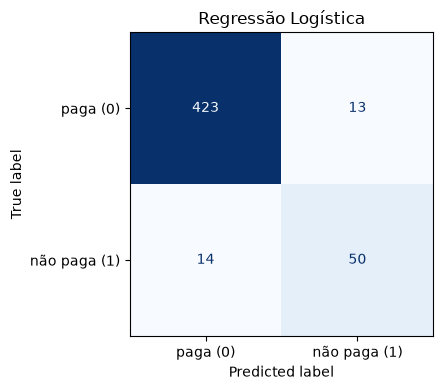

In [9]:
matriz_logistica = confusion_matrix(y_credit_teste, previsoes_logistica)
print(matriz_logistica)
print()

vn, fp, fn, vp = matriz_logistica.ravel()
print(f'Pagantes classificados corretamente: {vn}')
print(f'Pagantes classificados como não pagantes: {fp}')
print(f'Não pagantes classificados como pagantes: {fn}')
print(f'Não pagantes classificados corretamente: {vp}')
print()

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(matriz_logistica, display_labels=['paga (0)', 'não paga (1)']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Regressão Logística')
plt.tight_layout()
plt.show()

print(classification_report(y_credit_teste, previsoes_logistica, target_names=['paga (0)', 'não paga (1)']))

## 9. Comparação com os modelos da Parte 2

A Regressão Logística acertou **94,6%** (473 de 500). Ficou acima do Naive Bayes (93,8%), mas abaixo da Árvore de Decisão e da Random Forest, ambas com 98,2%.

A diferença aparece principalmente na classe 1 (não paga): precision 0,79 e recall 0,78. Isso significa que 14 dos 64 inadimplentes foram aprovados por engano. O modelo traça uma fronteira linear entre as classes, e nessa base a relação entre renda, idade e valor do empréstimo não é linear — daí o desempenho inferior ao das árvores, que conseguem dividir o espaço em regiões.

# Parte 4 - SVM

O SVM separa as classes por uma fronteira que deixa a maior margem possível entre elas. O parâmetro `C` controla a penalidade aplicada aos erros de treino: valores altos fazem o modelo se esforçar mais para acertar o treino, com risco de se ajustar demais (overfitting).

## 1. Kernel linear

O kernel define o formato da fronteira. O linear busca uma reta (ou hiperplano) e é o ponto de partida do exercício.

In [10]:
svm_linear = SVC(kernel='linear', C=1.0, random_state=1)
svm_linear.fit(X_credit_treino, y_credit_treino)

previsoes_svm_linear = svm_linear.predict(X_credit_teste)
acuracia_svm_linear = accuracy_score(y_credit_teste, previsoes_svm_linear)

print(f'Acurácia: {acuracia_svm_linear:.3f}')

Acurácia: 0.946


A acurácia foi **0,946**, igual ao valor esperado no enunciado.

## 2. Outros kernels

- **poly**: fronteira polinomial, com curvatura definida pelo grau;
- **sigmoid**: curva em forma de S, parecida com a usada em redes neurais;
- **rbf**: função gaussiana baseada na distância entre os pontos, o que permite fronteiras mais flexíveis.

In [11]:
resultados = []

for kernel in ['poly', 'sigmoid', 'rbf']:
    svm = SVC(kernel=kernel, C=1.0, random_state=1)
    svm.fit(X_credit_treino, y_credit_treino)
    acuracia = accuracy_score(y_credit_teste, svm.predict(X_credit_teste))
    resultados.append((kernel, acuracia))
    print(f'{kernel:8s} {acuracia:.4f}')

melhor_kernel, melhor_acuracia = max(resultados, key=lambda item: item[1])
print()
print('Melhor kernel:', melhor_kernel, f'({melhor_acuracia:.4f})')

poly     0.9680
sigmoid  0.8380
rbf      0.9820

Melhor kernel: rbf (0.9820)


O **rbf** teve o melhor resultado (0,982). O polinomial ficou em 0,968 e o sigmoide em 0,838, bem abaixo dos demais.

## 3. Variando C no kernel rbf

A ideia é verificar se aumentar a penalidade dos erros muda a acurácia.

In [12]:
for valor_c in [0.5, 1.0, 10, 50, 100]:
    svm = SVC(kernel=melhor_kernel, C=valor_c, random_state=1)
    svm.fit(X_credit_treino, y_credit_treino)
    acuracia = accuracy_score(y_credit_teste, svm.predict(X_credit_teste))
    print(f'C = {valor_c:6.1f}  acurácia = {acuracia:.4f}')

C =    0.5  acurácia = 0.9760
C =    1.0  acurácia = 0.9820
C =   10.0  acurácia = 0.9880
C =   50.0  acurácia = 0.9900
C =  100.0  acurácia = 0.9900


Sim, há mudança. A acurácia sobe de 0,976 com C = 0,5 para 0,990 com C = 50 e depois se estabiliza. Valores muito altos de C reduzem os erros no treino, mas podem piorar a generalização — por isso o passo seguinte testa as combinações com validação cruzada.

## 4. GridSearchCV

O GridSearch testa todas as combinações da grade e, para cada uma, faz validação cruzada com 5 partes do conjunto de treino. No fim devolve a combinação com a melhor média. `gamma` controla o alcance de cada ponto de treino nos kernels rbf, poly e sigmoide.

In [13]:
grade = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': ['scale', 'auto'],
}

busca = GridSearchCV(SVC(random_state=1), grade, cv=5, scoring='accuracy')
busca.fit(X_credit_treino, y_credit_treino)

print('Melhores parâmetros:', busca.best_params_)
print(f'Média na validação cruzada: {busca.best_score_:.4f}')

previsoes_svm_grid = busca.predict(X_credit_teste)
acuracia_svm_grid = accuracy_score(y_credit_teste, previsoes_svm_grid)
print(f'Acurácia no teste: {acuracia_svm_grid:.4f}')

Melhores parâmetros: {'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}
Média na validação cruzada: 0.9927
Acurácia no teste: 0.9900


A melhor combinação foi `{'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}`, com média de 0,9927 na validação cruzada e **0,990 (99,0%)** no teste. O GridSearch, portanto, foi melhor que o ajuste manual: 0,990 contra 0,982 do melhor resultado obtido variando C na mão.

[[435   1]
 [  4  60]]

              precision    recall  f1-score   support

    paga (0)       0.99      1.00      0.99       436
não paga (1)       0.98      0.94      0.96        64

    accuracy                           0.99       500
   macro avg       0.99      0.97      0.98       500
weighted avg       0.99      0.99      0.99       500



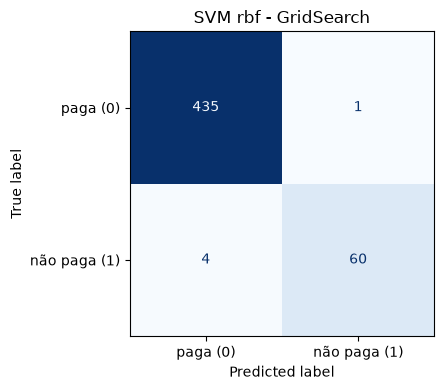

In [14]:
matriz_svm = confusion_matrix(y_credit_teste, previsoes_svm_grid)
print(matriz_svm)
print()

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(matriz_svm, display_labels=['paga (0)', 'não paga (1)']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('SVM rbf - GridSearch')
plt.tight_layout()
plt.show()

print(classification_report(y_credit_teste, previsoes_svm_grid, target_names=['paga (0)', 'não paga (1)']))

# Comparação dos quatro algoritmos

A célula abaixo treina novamente os modelos das Partes 1 e 2 para deixar todos os resultados no mesmo notebook, com a mesma divisão de treino e teste.

In [15]:
# Modelos das Partes 1 e 2
naive_bayes = GaussianNB().fit(X_credit_treino, y_credit_treino)
arvore = DecisionTreeClassifier(criterion='entropy', random_state=0).fit(X_credit_treino, y_credit_treino)
floresta = RandomForestClassifier(n_estimators=100, criterion='entropy', random_state=0).fit(X_credit_treino, y_credit_treino)

modelos = {
    'Naive Bayes': naive_bayes,
    'Regressão Logística': modelo_credit,
    'SVM linear': svm_linear,
    'SVM rbf (C=1)': SVC(kernel='rbf', C=1.0, random_state=1).fit(X_credit_treino, y_credit_treino),
    'Árvore de Decisão': arvore,
    'Random Forest (100)': floresta,
    'SVM GridSearch': busca.best_estimator_,
}

linhas = []
for nome, modelo in modelos.items():
    previsao = modelo.predict(X_credit_teste)
    acuracia = accuracy_score(y_credit_teste, previsao)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_credit_teste, previsao, average=None, zero_division=0
    )
    linhas.append({
        'Modelo': nome,
        'Acurácia (%)': round(acuracia * 100, 2),
        'Precision (não paga)': round(precision[1], 2),
        'Recall (não paga)': round(recall[1], 2),
        'F1 (não paga)': round(f1[1], 2),
    })

tabela = pd.DataFrame(linhas).sort_values('Acurácia (%)', ascending=False)
tabela.reset_index(drop=True, inplace=True)
print(tabela.to_string(index=False))

             Modelo  Acurácia (%)  Precision (não paga)  Recall (não paga)  F1 (não paga)
     SVM GridSearch          99.0                  0.98               0.94           0.96
      SVM rbf (C=1)          98.2                  0.97               0.89           0.93
  Árvore de Decisão          98.2                  0.91               0.95           0.93
Random Forest (100)          98.2                  0.95               0.91           0.93
Regressão Logística          94.6                  0.79               0.78           0.79
         SVM linear          94.6                  0.78               0.80           0.79
        Naive Bayes          93.8                  0.84               0.64           0.73


## Análise

O SVM com GridSearch teve o melhor desempenho geral: 99,0% de acurácia e apenas 5 erros em 500 clientes. A Árvore de Decisão e a Random Forest ficaram em 98,2%, com perfis diferentes: a árvore tem recall maior na classe 1 (0,95, ou seja, deixa passar menos inadimplentes), enquanto a floresta é mais precisa (0,95, com menos falsos alarmes).

Naive Bayes (93,8%), Regressão Logística (94,6%) e SVM linear (94,6%) ficaram atrás. Os dois últimos usam fronteiras lineares e esbarram na relação não linear entre os atributos; o Naive Bayes ainda assume que os atributos são independentes, o que não vale para essa base.

Para o banco, o erro mais caro é aprovar um cliente que não vai pagar. Nesse critério a Árvore de Decisão continua competitiva pelo recall de 0,95, enquanto o SVM ajustado pelo GridSearch oferece o melhor equilíbrio entre acurácia e recall.